In [85]:
import sys
import os
sys.path.append(os.path.abspath("src"))

In [86]:
import random, numpy as np, torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [87]:
print('seed test:', torch.rand(1).item(), np.random.rand())

seed test: 0.8822692632675171 0.3745401188473625


In [88]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from arc.Binary_Architecture import Model
import os
from data.Data_Interface import DataInterface
from model.Model_Interface import ModelInterface
from cf.DiPACE import DiPACE
from cf.DiPACE_Plus import DiPACE_Plus
from cf.GradCFA import DiPACE_FA
from eval.Evaluation import Evaluate
pd.set_option('display.max_columns', None)

In [89]:
df = pd.read_csv('datasets/credit.csv')
df = df.drop(columns='ZipCode')

In [90]:
print(df.shape)

(690, 15)


In [91]:
encoder = LabelEncoder()
df['Industry'] = encoder.fit_transform(df['Industry'])
label_mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
print(label_mapping)
df['Ethnicity'] = encoder.fit_transform(df['Ethnicity'])
label_mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
print(label_mapping)
df['Citizen'] = encoder.fit_transform(df['Citizen'])
label_mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
print(label_mapping)

{'CommunicationServices': 0, 'ConsumerDiscretionary': 1, 'ConsumerStaples': 2, 'Education': 3, 'Energy': 4, 'Financials': 5, 'Healthcare': 6, 'Industrials': 7, 'InformationTechnology': 8, 'Materials': 9, 'Real Estate': 10, 'Research': 11, 'Transport': 12, 'Utilities': 13}
{'Asian': 0, 'Black': 1, 'Latino': 2, 'Other': 3, 'White': 4}
{'ByBirth': 0, 'ByOtherMeans': 1, 'Temporary': 2}


In [92]:
X = df.drop(columns=['Approved'])
y = df['Approved']

In [93]:
X = pd.get_dummies(X, columns=['Gender', 'Married', 'BankCustomer', 'Industry', 'Ethnicity', 'PriorDefault', 'CreditScore', 'Employed', 'DriversLicense', 'Citizen'])

In [94]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [95]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_scaled = scaler.transform(X)

In [96]:
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

In [97]:
input_size = X_train.shape[1]
model = Model(input_size)

In [98]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [99]:
print('weights checksum:', sum(p.sum().item() for p in model.parameters()))

weights checksum: 0.2995562255382538


In [100]:
epochs = 100
for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()
    
    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item()}')

Epoch [10/100], Loss: 0.6269097328186035
Epoch [20/100], Loss: 0.5406067371368408
Epoch [30/100], Loss: 0.43789467215538025
Epoch [40/100], Loss: 0.3481309413909912
Epoch [50/100], Loss: 0.28542473912239075
Epoch [60/100], Loss: 0.2432221621274948
Epoch [70/100], Loss: 0.21342213451862335
Epoch [80/100], Loss: 0.18987402319908142
Epoch [90/100], Loss: 0.16987968981266022
Epoch [100/100], Loss: 0.15236812829971313


In [101]:
with torch.no_grad():
    model.eval()
    outputs = model(X_test_tensor)
    predicted = (outputs >= 0.5).float()
    accuracy = (predicted == y_test_tensor).sum().item() / y_test.shape[0]
    print(f'Test Accuracy: {accuracy}')

Test Accuracy: 0.8260869565217391


In [102]:
model_path = 'pytorch_model.pth'
torch.save(model.state_dict(), model_path)

In [103]:
d = DataInterface(dataframe=df, target='Approved', continuous_features=['Age', 'Debt', 'YearsEmployed', 'Income'])
m = ModelInterface(model_path='pytorch_model.pth', input_size = input_size)

In [104]:
df = df[df['Approved']==0]
query_index = np.random.choice(len(df))
query_instance = df.iloc[query_index].drop('Approved').to_list()
print(query_index)

348


Desired class: tensor([1.], grad_fn=<RsubBackward1>)
Original class tensor([0.], grad_fn=<RoundBackward0>)
All CFs are classified as the desired class.
Final Loss: tensor(0.9300, grad_fn=<SubBackward0>)
Final Pred Loss: tensor(0., grad_fn=<MeanBackward0>)
Final Proximity Loss: tensor(0.3233, grad_fn=<MeanBackward0>)
Final Diversity Loss: tensor(0.9173, grad_fn=<LinalgDetBackward0>)
Final Sparsity Loss: tensor(0.3607)
Final Plausibility Loss: tensor(2.5167, grad_fn=<MeanBackward0>)
Unacceptably high loss. Perturbing relevant features.
All CFs are classified as the desired class.
Final Loss: tensor(0.5034, grad_fn=<SubBackward0>)
Final Pred Loss: tensor(0., grad_fn=<MeanBackward0>)
Final Proximity Loss: tensor(0.3063, grad_fn=<MeanBackward0>)
Final Diversity Loss: tensor(0.9397, grad_fn=<LinalgDetBackward0>)
Final Sparsity Loss: tensor(0.2951)
Final Plausibility Loss: tensor(1.5898, grad_fn=<MeanBackward0>)
Query instance:      Age  Debt  YearsEmployed  Income  Gender  Married  BankCusto

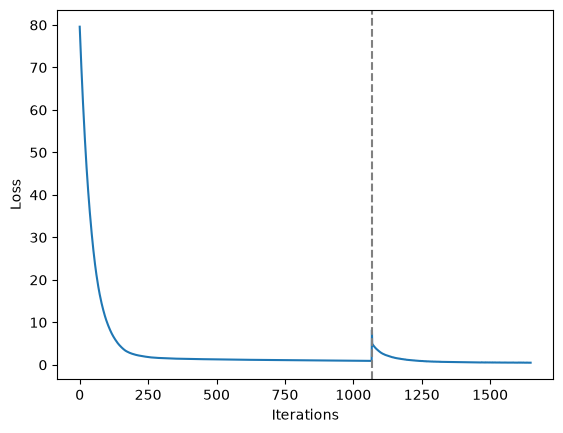

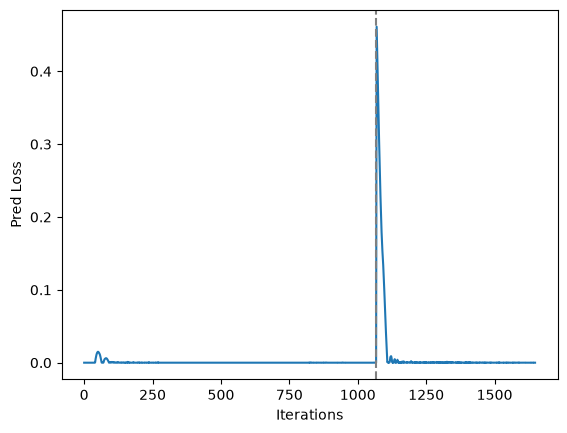

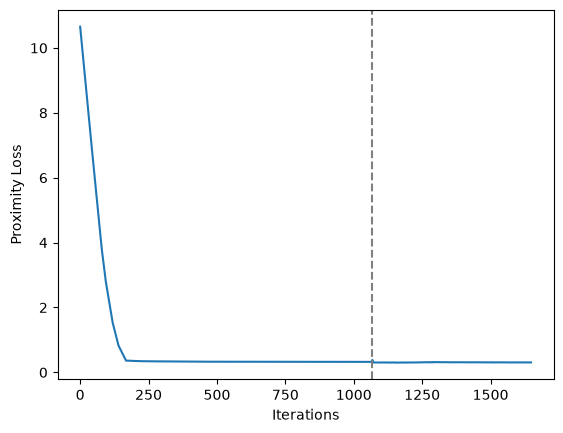

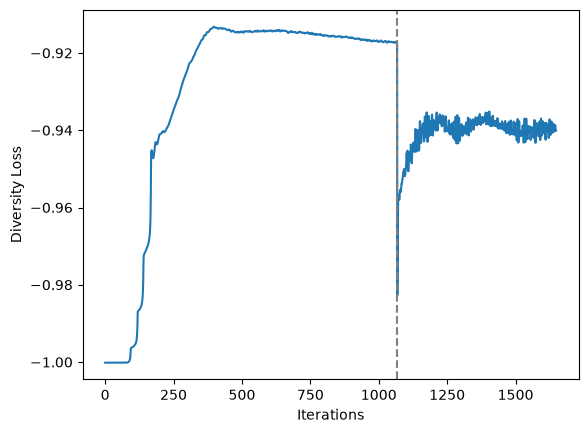

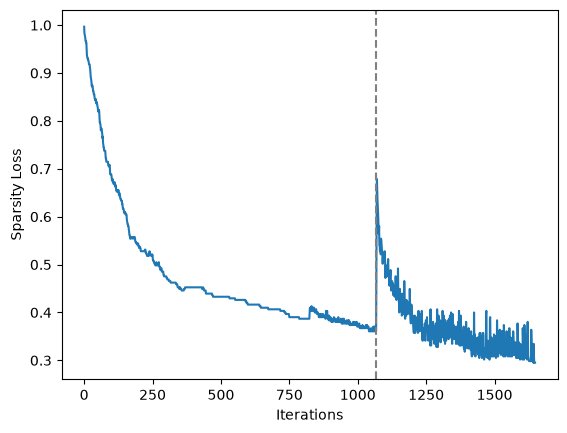

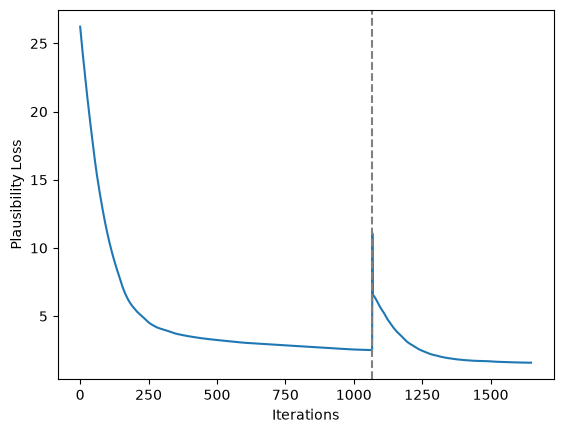

In [105]:
exp = DiPACE(d, m)
cf = exp.generate_counterfactuals(query_instance, total_CFs=5, high_loss_threshold=0.7)

In [106]:
query_instance, cf_instances = cf
query_instance = torch.Tensor(query_instance).float()
cf_instances = torch.Tensor(cf_instances).float()

In [107]:
ev = Evaluate(d, m)
print('Proximity:   ', ev.evaluate_proximity(query_instance, cf_instances))
print('Sparsity:    ', ev.evaluate_sparsity(query_instance, cf_instances))
print('Diversity:   ', ev.evaluate_diversity(cf_instances))
print('Plausibility:', ev.evaluate_plausibility(cf_instances, d.norm_encoded_features, k=1))
print('Confidence:  ', ev.evaluate_confidence(cf_instances, desired_class=1))

Proximity:    tensor(0.2686)
Sparsity:     tensor(0.2951)
Diversity:    tensor(0.8224)
Plausibility: tensor(1.9169)
Confidence:   tensor(0.7924, grad_fn=<MeanBackward0>)
